In [1]:
# Cell 1: path dan import
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data_loader import load_data, load_model
from src.evaluation import compare_methods, alpha_sweep
os.makedirs("../reports", exist_ok=True)

In [2]:
# Cell 2: muat data dan model
X, G, movies, genres = load_data()
U, V, asli = load_model(len(X))
print("U dari FCM" if asli else "PERINGATAN: U masih acak (placeholder)")

U dari FCM


In [3]:
# Cell 3: bandingkan fuzzy vs KNN biasa untuk beberapa k
hasil = []
for k in [5, 10, 20]:
    r = compare_methods(X, U, G, k=k, alpha=0.5, n_queries=500, seed=42)
    hasil.append(r)
tabel = pd.DataFrame(hasil)
tabel.to_csv("../reports/perbandingan_metode.csv", index=False)
tabel

,precision_fuzzy,precision_baseline,selisih,alpha,k
0,0.9944,0.9952,-0.0008,0.5,5
1,0.9916,0.9938,-0.0022,0.5,10
2,0.9872,0.9918,-0.0046,0.5,20


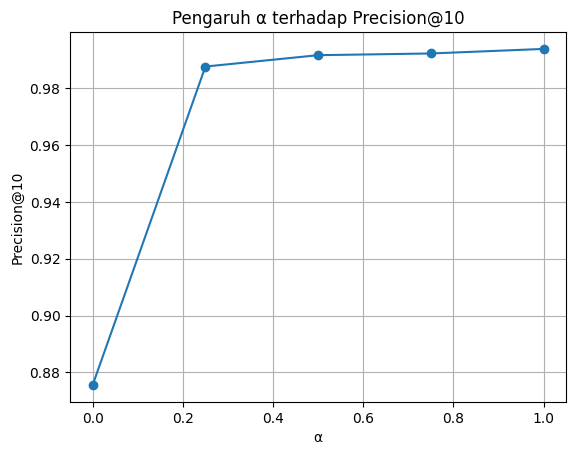

In [4]:
# Cell 4: pengaruh alpha
sweep = pd.DataFrame(alpha_sweep(X, U, G, k=10, n_queries=500, seed=42))
sweep.to_csv("../reports/alpha_sweep.csv", index=False)
plt.plot(sweep["alpha"], sweep["precision"], marker="o")
plt.xlabel("α"); plt.ylabel("Precision@10"); plt.title("Pengaruh α terhadap Precision@10")
plt.grid(True); plt.savefig("../reports/alpha_sweep.png", dpi=150); plt.show()